# Отрисовка спектрограмм

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import detrend, cwt, morlet2
from pathlib2 import Path
from wavelet_analysis import morlet_power_matrix
from spectrogram_visualization import plot_wavelet_comparison

### Инициализация путей

In [2]:
work_dir = Path(r"C:\Users\alvar\Documents\practice\test_repo_spectral_analysis")
path_to_data = work_dir / "sum_edges_triples"
path_to_data.mkdir(exist_ok=True, parents=True)
path_to_save_figure = work_dir / "figures" / "spectrograms"
path_to_save_figure.mkdir(exist_ok=True, parents=True)

### Настройка параметров для рисунка

In [3]:

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2,
    "xtick.major.size": 5,
    "ytick.major.size": 5,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})


### Загрузка данных

In [4]:
data_native = np.load(path_to_data/'native_manual_sum_edges_triples.npz')
data_synthetic = np.load(path_to_data/'sum_edges_triples_synthetic_data.npz')
native_triples = data_native["sum_triples"]
synthetic_triples = data_synthetic["sum_triples"]

### Определение параметров

In [5]:
fs = 20
w = 6

frequencies = np.linspace(0.1, 10.0, 500)
# frequencies = np.logspace(-20, 50, 500)

# Экспериментальный и синтетический сигналы
signals = [
    ("Part of mouse brain", np.asarray(native_triples, dtype=float)),
    ("Part of LLM layer (Qwen2.5-1.5B)", np.asarray(synthetic_triples, dtype=float)),
]

### Расчет локального вейвлетного спектра

In [6]:
results = []

for title, signal_data in signals:

    power = morlet_power_matrix(signal_data, fs=fs, frequencies=frequencies, w=w)
    power_db = 10 * np.log10(power + 1e-10)
    times = np.arange(len(signal_data)) / fs
    signal_cleaned = detrend(signal_data)
    
    results.append({
        "title": title,
        "times": times,
        "signal": signal_data,
        "signal_cleaned": signal_cleaned,
        "power_db": power_db
    })

# Общая цветовая шкала для обеих спектрограмм
all_power = np.concatenate([
    result["power_db"].ravel()
    for result in results
])

vmin, vmax = np.nanpercentile(all_power, [5, 99])

### Отрисовка спектрограммы

In [7]:
# Параметры интересующих событий, время в секундах
bursts = [502, 717, 800]  # всплески — оранжевые
dips = [185, 702, 780]    # провалы — фиолетовые

half_width_sec = 5  # полуширина выделенной зоны, секунды


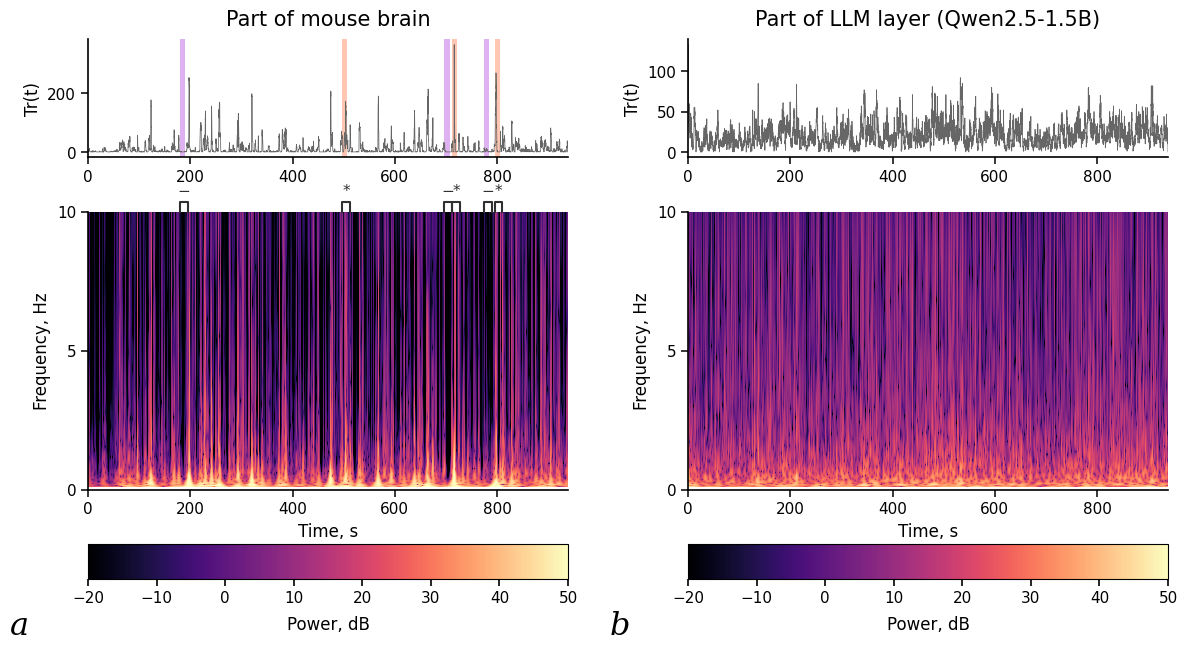

In [8]:
fig = plot_wavelet_comparison(
    results=results,
    frequencies=frequencies,

    bursts=bursts,
    dips=dips,
    half_width_sec=half_width_sec,

    power_limits=(-20, 50),
    frequency_limits=(0, 10),
    frequency_ticks=[0, 5, 10],

    cmap="magma",
    figsize=(12, 6.5),

    save_dir=path_to_save_figure,
    figure_name="mouse_vs_qwen_wavelet"
)